
# 05 — Understanding Winger Playstyle Structure

## Decoding Winger Playstyles

The previous four notebooks established a historical winger population and constructed a 20-feature representation of attacking behaviour.

The representation describes **how players tend to attack**, rather than how effectively those actions produce goals or assists.

The current dataset contains 1,396 player × club × season observations across Europe's Big Five leagues from 2017–18 to 2023–24.

### Central research question

**What are the dominant behavioural dimensions underlying winger attacking playstyles?**

Wingers can differ in several related ways:

- advanced positional involvement and progressive receiving;
- carrying and direct dribbling;
- progression through passing versus carrying;
- crossing and ball delivery;
- shooting frequency and shot location;
- entering the penalty area versus supplying it.

These tendencies may be correlated rather than independently distributed.

For example, players who frequently receive possession in advanced areas may also carry into the box and shoot more often. Other players may progress attacks primarily through passing and crossing.

We want to investigate these relationships systematically before attempting to identify player archetypes.

## Analytical approach

**Principal Component Analysis (PCA)** will be used as an exploratory tool to examine the structure of the standardized attacking-style feature space.

Specifically, we will investigate:

1. How much variation is captured by successive principal components?
2. Which features contribute most strongly to each component?
3. What football behaviours might the resulting dimensions represent?
4. Which player-season observations exemplify opposite ends of those dimensions?
5. How sensitive is this structure to feature-family weighting?

PCA is not automatically assumed to be the final representation for similarity analysis or clustering.

Component interpretations must be supported by both feature loadings and observed player profiles.

Goals, assists, finishing efficiency, and other quality/output variables remain excluded from the initial style-space analysis.



# 1. Data Loading and Validation

Notebook 04 exported three representations of the retained features:

1. **Raw feature matrix:** Original behavioural units, useful for football interpretation.
2. **Standardized feature matrix:** Globally standardized features; the primary input for PCA.
3. **Family-balanced matrix:** Standardized features with additional family weighting, reserved for sensitivity analysis.

It also exported a feature specification containing the retained feature names and their conceptual families.

The observational grain remains:

**player × club × season**

Transfer spells are preserved separately because a player's tactical role and attacking behaviour may differ across clubs.

Repeated observations of the same footballer across seasons are also preserved. Consequently, this analysis describes variation among qualifying player spells, not a population of independent player identities.

The current feature set is treated as finalized following Notebook 04's redundancy review.

Before PCA, we verify that the exported matrices preserve the established sample and preprocessing decisions.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

OUTPUT_DIR = Path("/content/")

required_files = [
    "winger_style_features_raw.parquet",
    "winger_style_features_scaled.parquet",
    "winger_style_features_family_balanced.parquet",
    "winger_style_feature_specification.csv",
]

missing_files = [
    name for name in required_files
    if not (OUTPUT_DIR / name).exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing Notebook 04 exports: "
        f"{missing_files}. Regenerate or upload "
        "the updated 20-feature artifacts."
    )

print("All required files found.")

All required files found.


In [3]:
raw_df = pd.read_parquet(
    OUTPUT_DIR / "winger_style_features_raw.parquet"
)

scaled_df = pd.read_parquet(
    OUTPUT_DIR / "winger_style_features_scaled.parquet"
)

balanced_df = pd.read_parquet(
    OUTPUT_DIR / "winger_style_features_family_balanced.parquet"
)

feature_spec = pd.read_csv(
    OUTPUT_DIR / "winger_style_feature_specification.csv"
)

identity_cols = [
    "player",
    "player_id",
    "squad",
    "comp",
    "season",
    "age",
    "born",
    "Minutes"
]

features = feature_spec["feature"].tolist()

print("Raw matrix:", raw_df.shape)
print("Scaled matrix:", scaled_df.shape)
print("Family-balanced matrix:", balanced_df.shape)
print("Retained features:", len(features))

display(
    feature_spec[
        ["feature", "macro_family", "family"]
    ]
)

Raw matrix: (1396, 28)
Scaled matrix: (1396, 28)
Family-balanced matrix: (1396, 28)
Retained features: 20


,feature,macro_family,family
0,attacking_third_touch_share,Territory,Territory
1,box_penetration_touch_share,Territory,Territory
2,progressive_receptions_p90,Receiving,Receiving
3,progressive_reception_share,Receiving,Receiving
4,progressive_carries_p90,Carrying,Carrying
5,progressive_carry_share,Carrying,Carrying
6,carries_into_box_p90,Carrying,Carrying
7,take_ons_p90,Dribbling,Dribbling
8,take_ons_per_100_live_touches,Dribbling,Dribbling
9,progressive_passes_p90,Passing,Passing


In [4]:
# Canonical population and feature count
assert len(raw_df) == 1396
assert len(scaled_df) == 1396
assert len(balanced_df) == 1396

assert len(features) == 20
assert len(set(features)) == 20

assert "progressive_distance_per_carry" not in features

expected_cols = identity_cols + features

for name, table in {
    "Raw": raw_df,
    "Scaled": scaled_df,
    "Family-balanced": balanced_df
}.items():

    assert table.columns.tolist() == expected_cols, (
        f"{name} matrix has unexpected columns or order."
    )

    assert not table.duplicated(
        subset=["player_id", "squad", "season"]
    ).any(), f"{name} matrix contains duplicate spells."

    assert table[identity_cols].notna().all().all()

    assert table[features].notna().all().all()

    assert np.isfinite(
        table[features].to_numpy(dtype=float)
    ).all()


# Verify exact row alignment across matrices
for other in [raw_df, balanced_df]:

    pd.testing.assert_frame_equal(
        scaled_df[identity_cols].reset_index(drop=True),
        other[identity_cols].reset_index(drop=True)
    )


# Verify standardization
X = scaled_df[features].copy()

scaling_audit = pd.DataFrame({
    "mean": X.mean(),
    "std_population": X.std(ddof=0)
})

assert np.allclose(
    scaling_audit["mean"], 0, atol=1e-8
)

assert np.allclose(
    scaling_audit["std_population"], 1, atol=1e-6
)

print("All population, alignment and scaling checks passed.")

print("\nSeason coverage:")
display(
    scaled_df["season"]
    .value_counts()
    .sort_index()
    .rename("observations")
    .to_frame()
)

print("\nFinal feature-family distribution:")
display(
    feature_spec["macro_family"]
    .value_counts()
    .rename("n_features")
    .to_frame()
)

print("\nScaling audit:")
display(scaling_audit.round(6))

All population, alignment and scaling checks passed.

Season coverage:


,observations
season,
2017-2018,226
2018-2019,202
2019-2020,175
2020-2021,205
2021-2022,185
2022-2023,213
2023-2024,190



Final feature-family distribution:


,n_features
macro_family,
Passing,4
Carrying,3
Shooting,3
Territory,2
Dribbling,2
Receiving,2
Crossing,2
Behavioural Choice,2



Scaling audit:


,mean,std_population
attacking_third_touch_share,0.0,1.0
box_penetration_touch_share,0.0,1.0
progressive_receptions_p90,0.0,1.0
progressive_reception_share,-0.0,1.0
progressive_carries_p90,0.0,1.0
progressive_carry_share,-0.0,1.0
carries_into_box_p90,0.0,1.0
take_ons_p90,0.0,1.0
take_ons_per_100_live_touches,-0.0,1.0
progressive_passes_p90,-0.0,1.0



# 2. Principal Component Analysis

## 2.1 PCA on the Primary Standardized Representation

The primary PCA uses the globally standardized 20-feature matrix constructed in Notebook 04.

PCA identifies orthogonal linear combinations of features that successively maximize the variance captured across player-spell observations.

Because the inputs have already been standardized, no additional normalization is applied.

All 20 principal components are initially retained for inspection.

We do not impose an explained-variance threshold or select a reduced dimensionality in advance.

### First diagnostic: explained variance

We examine:

- explained variance ratio of each principal component;
- cumulative explained variance;
- the shape of the scree plot.

A steep concentration of variance in the first few components would suggest that many engineered behaviours vary together along a smaller number of dominant axes.

A more gradual distribution would suggest that winger playstyle variation is spread across more dimensions.

Neither outcome is inherently preferable.

**Important:** Explained variance is not a measure of player quality, predictive accuracy, or the football importance of a component.


In [5]:
pca = PCA()

pca_scores = pca.fit_transform(X)

n_components = pca.n_components_

variance_df = pd.DataFrame({
    "component": [
        f"PC{i}" for i in range(1, n_components + 1)
    ],
    "explained_variance_ratio": (
        pca.explained_variance_ratio_
    )
})

variance_df["explained_variance_pct"] = (
    variance_df["explained_variance_ratio"] * 100
)

variance_df["cumulative_variance_pct"] = (
    variance_df["explained_variance_pct"].cumsum()
)

assert n_components == 20

assert np.isclose(
    pca.explained_variance_ratio_.sum(), 1.0
)

print("PCA components:", n_components)

display(
    variance_df[
        [
            "component",
            "explained_variance_pct",
            "cumulative_variance_pct"
        ]
    ].round(2)
)

PCA components: 20


,component,explained_variance_pct,cumulative_variance_pct
0,PC1,35.56,35.56
1,PC2,19.32,54.88
2,PC3,14.01,68.89
3,PC4,8.51,77.40
4,PC5,7.83,85.23
5,PC6,3.34,88.57
6,PC7,2.86,91.43
7,PC8,2.16,93.60
8,PC9,1.78,95.38
9,PC10,1.22,96.60


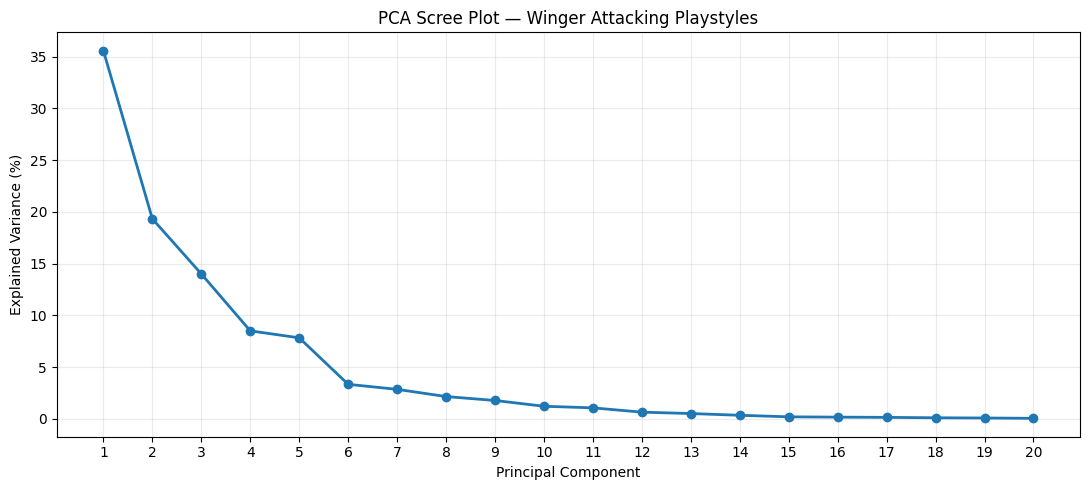

In [6]:
components = np.arange(1, n_components + 1)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    components,
    variance_df["explained_variance_pct"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "PCA Scree Plot — Winger Attacking Playstyles"
)

ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance (%)")

ax.set_xticks(components)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

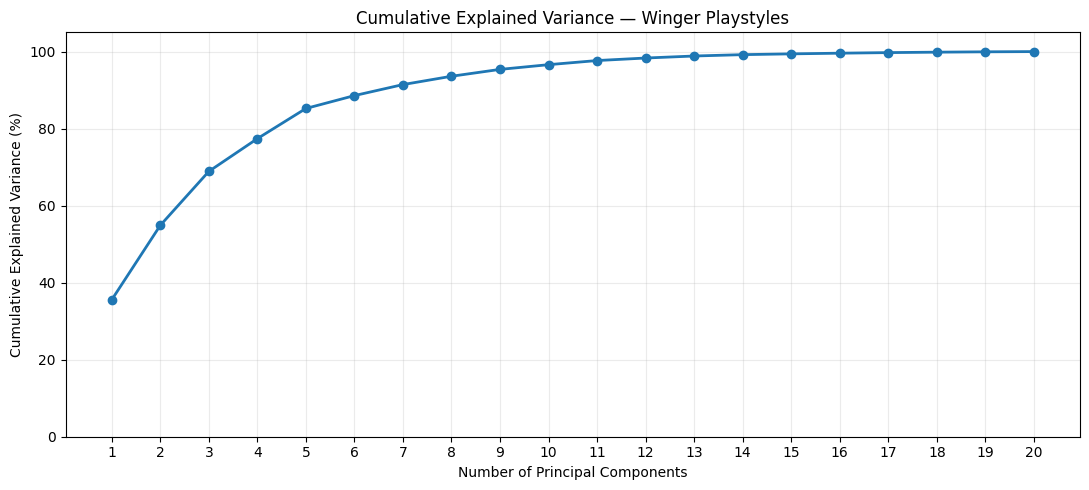

50% variance reached with 2 components
70% variance reached with 4 components
80% variance reached with 5 components
90% variance reached with 7 components


In [7]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    components,
    variance_df["cumulative_variance_pct"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Cumulative Explained Variance — Winger Playstyles"
)

ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance (%)")

ax.set_xticks(components)
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# Descriptive milestones, not selection rules
for threshold in [50, 70, 80, 90]:

    n_needed = np.searchsorted(
        variance_df["cumulative_variance_pct"].to_numpy(),
        threshold
    ) + 1

    print(
        f"{threshold}% variance reached with "
        f"{n_needed} components"
    )


## 2.2 Interpreting Principal Components

The explained-variance analysis shows that the first five components
capture 85.23% of the total standardized feature variance.

However, explained variance does not reveal the football meaning
of each component.

To investigate this, we examine two related quantities:

**PCA coefficients**

The weights assigned to each standardized feature when constructing
a principal component.

**Feature-component correlations**

The Pearson correlation between each original standardized feature
and the resulting component scores.

These correlations help explain which observed attacking behaviours
are strongly associated with each component.

Positive and negative values represent opposite directions along
the component, not good and bad football performance.

The overall sign of a principal component is arbitrary: reversing
every coefficient and score leaves the PCA solution unchanged.

We first inspect the five leading components without assigning
football labels in advance.


In [8]:
# Names for all principal components
pc_names = [
    f"PC{i}"
    for i in range(1, pca.n_components_ + 1)
]

focus_pcs = pc_names[:5]

# PCA coefficients: weights of standardized features
pca_coefficients = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=pc_names
)

# Observation-level PCA scores
scores_df = pd.DataFrame(
    pca_scores,
    index=X.index,
    columns=pc_names
)

# Correlation of original features with PCA scores
feature_pc_corr = pd.DataFrame({
    pc: X.corrwith(scores_df[pc])
    for pc in pc_names
})

# Attach football feature families
family_map = (
    feature_spec
    .set_index("feature")["macro_family"]
)

loading_summary = feature_pc_corr[
    focus_pcs
].copy()

loading_summary.insert(
    0,
    "macro_family",
    family_map.loc[loading_summary.index]
)

print("Feature correlations with the first five PCs:")
display(loading_summary.round(3))

Feature correlations with the first five PCs:


,macro_family,PC1,PC2,PC3,PC4,PC5
attacking_third_touch_share,Territory,0.766,0.317,0.067,0.280,-0.224
box_penetration_touch_share,Territory,0.689,-0.510,-0.213,0.266,-0.025
progressive_receptions_p90,Receiving,0.690,0.370,-0.110,0.238,-0.427
progressive_reception_share,Receiving,0.758,-0.100,0.298,0.259,-0.290
progressive_carries_p90,Carrying,0.688,0.567,-0.149,-0.232,0.033
progressive_carry_share,Carrying,0.792,0.209,0.207,-0.226,0.151
carries_into_box_p90,Carrying,0.851,0.279,-0.194,-0.042,-0.041
take_ons_p90,Dribbling,0.622,0.396,-0.189,-0.369,0.355
take_ons_per_100_live_touches,Dribbling,0.706,0.093,-0.002,-0.371,0.441
progressive_passes_p90,Passing,-0.355,0.633,-0.638,-0.008,-0.040


In [9]:
for pc in focus_pcs:

    correlations = feature_pc_corr[pc]

    print("\n" + "=" * 65)
    print(
        f"{pc} — Explained variance: "
        f"{variance_df.loc[pc_names.index(pc), 'explained_variance_pct']:.2f}%"
    )
    print("=" * 65)

    strongest_positive = (
        correlations.sort_values(ascending=False)
        .head(5)
    )

    strongest_negative = (
        correlations.sort_values()
        .head(5)
    )

    print("\nHighest positive associations:")
    display(
        pd.DataFrame({
            "correlation": strongest_positive,
            "macro_family": family_map.loc[
                strongest_positive.index
            ]
        }).round(3)
    )

    print("Lowest / most negative associations:")
    display(
        pd.DataFrame({
            "correlation": strongest_negative,
            "macro_family": family_map.loc[
                strongest_negative.index
            ]
        }).round(3)
    )


PC1 — Explained variance: 35.56%

Highest positive associations:


,correlation,macro_family
carries_into_box_p90,0.851,Carrying
carry_progression_share,0.842,Behavioural Choice
carry_box_entry_share,0.814,Behavioural Choice
progressive_carry_share,0.792,Carrying
attacking_third_touch_share,0.766,Territory


Lowest / most negative associations:


,correlation,macro_family
long_pass_share,-0.482,Passing
avg_shot_distance,-0.474,Shooting
progressive_passes_p90,-0.355,Passing
progressive_pass_share,-0.240,Passing
crosses_p90,-0.171,Crossing



PC2 — Explained variance: 19.32%

Highest positive associations:


,correlation,macro_family
passes_into_box_p90,0.779,Passing
crosses_p90,0.733,Crossing
progressive_passes_p90,0.633,Passing
progressive_carries_p90,0.567,Carrying
long_pass_share,0.530,Passing


... (10 outputs left out)


PC5 — Explained variance: 7.83%

Highest positive associations:


,correlation,macro_family
shots_per_100_att3rd_touches,0.574,Shooting
avg_shot_distance,0.507,Shooting
take_ons_per_100_live_touches,0.441,Dribbling
take_ons_p90,0.355,Dribbling
shots_p90,0.325,Shooting


Lowest / most negative associations:


,correlation,macro_family
progressive_receptions_p90,-0.427,Receiving
progressive_reception_share,-0.290,Receiving
passes_into_box_p90,-0.252,Passing
attacking_third_touch_share,-0.224,Territory
crosses_p90,-0.066,Crossing


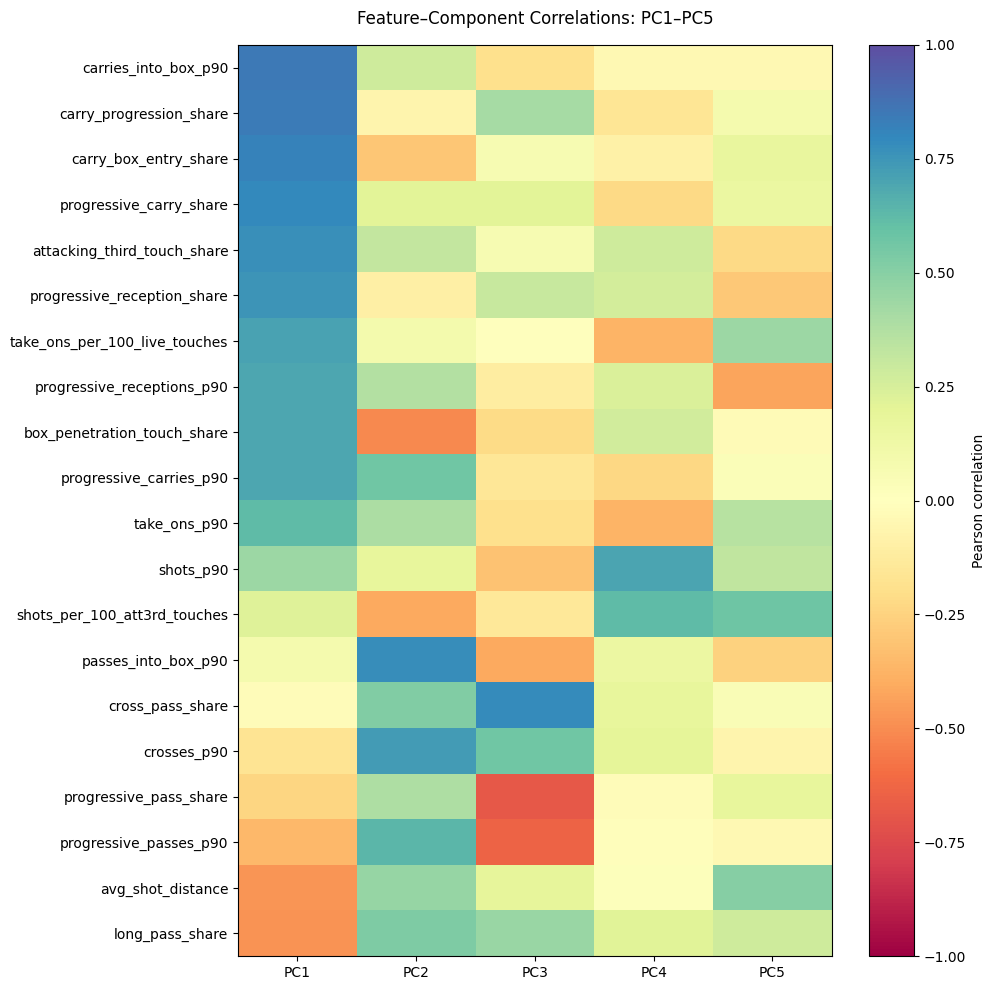

In [11]:

plot_data = feature_pc_corr[
    focus_pcs
].sort_values("PC1", ascending=False)

fig, ax = plt.subplots(figsize=(10, 10))

im = ax.imshow(
    plot_data.values,
    aspect="auto",
    cmap="Spectral",
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    np.arange(len(focus_pcs)),
    labels=focus_pcs
)

ax.set_yticks(
    np.arange(len(plot_data.index)),
    labels=plot_data.index
)

ax.set_title(
    "Feature–Component Correlations: PC1–PC5",
    pad=15
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Pearson correlation")

plt.tight_layout()
plt.show()



## 2.3 Player-Level Interpretation of Principal Components

Feature-component correlations suggest that the leading PCA dimensions
represent distinct combinations of attacking behaviours.

However, mathematical associations alone do not establish that these
dimensions have meaningful football interpretations.

We therefore examine player-season observations located at the positive
and negative extremes of PC1–PC5.

For each component, we investigate:

1. Which player spells occupy the highest and lowest positions?
2. Are these examples consistent with the proposed behavioural interpretation?
3. Do their original attacking metrics support that interpretation?
4. Are there surprising examples that reveal weaknesses in our descriptions?

Because players may appear across multiple seasons, the displayed
examples are restricted to one spell per player within each extreme.
This prevents a few repeatedly observed footballers from dominating
the interpretation tables.

This restriction applies only to example selection. All 1,396
observations remain in the PCA.

Importantly, these are internal interpretability checks using the
same data used to fit PCA, not independent external validation.

High component scores do not imply better players, and negative scores
do not imply worse players.


In [12]:
# Attach PCA scores to the canonical observation identities
player_pca_df = scaled_df[identity_cols].copy()

player_pca_df[focus_pcs] = scores_df[
    focus_pcs
].to_numpy()

n_examples = 6

pc_extremes = {}

for pc in focus_pcs:

    positive = (
        player_pca_df
        .sort_values(pc, ascending=False)
        .drop_duplicates(subset=["player_id"])
        .head(n_examples)
        .copy()
    )

    negative = (
        player_pca_df
        .sort_values(pc, ascending=True)
        .drop_duplicates(subset=["player_id"])
        .head(n_examples)
        .copy()
    )

    positive["direction"] = "High"
    negative["direction"] = "Low"

    pc_extremes[pc] = {
        "high": positive,
        "low": negative
    }

    examples = pd.concat(
        [positive, negative]
    )

    print("\n" + "=" * 65)
    print(f"{pc} — Extreme Player Spells")
    print("=" * 65)

    display(
        examples[
            [
                "direction",
                "player",
                "squad",
                "season",
                "Minutes",
                pc
            ]
        ].round(2)
    )


PC1 — Extreme Player Spells


,direction,player,squad,season,Minutes,PC1
1251,High,Jeremy Doku,Manchester City,2023-2024,1595,12.00
502,High,Vinicius Júnior,Real Madrid,2019-2020,1364,8.66
522,High,Kylian Mbappé,Paris S-G,2019-2020,1513,7.96
843,High,Arnaut Danjuma,Villarreal,2021-2022,1472,6.84
838,High,Samuel Chukwueze,Villarreal,2021-2022,1333,6.79
1314,High,Kaoru Mitoma,Brighton,2023-2024,1486,6.68
28,Low,Chris Brunt,West Brom,2017-2018,1920,-7.81
527,Low,Jon Moncayola,Osasuna,2019-2020,1496,-7.46
59,Low,Fayçal Fajr,Getafe,2017-2018,2385,-7.42
1,Low,Romain Amalfitano,Dijon,2017-2018,2703,-7.40



PC2 — Extreme Player Spells


,direction,player,squad,season,Minutes,PC2
143,High,Neymar,Paris S-G,2017-2018,1786,6.69
1245,High,Ousmane Dembélé,Paris S-G,2023-2024,1506,6.18
464,High,Ángel Di María,Paris S-G,2019-2020,2000,6.15
352,High,Lionel Messi,Barcelona,2018-2019,2713,5.78
316,High,Adnan Januzaj,Real Sociedad,2018-2019,1254,5.44
4,High,Felipe Anderson,Lazio,2017-2018,1162,5.20
713,Low,Rafa Mir,Huesca,2020-2021,2877,-5.95
798,Low,Hwang Ui-jo,Bordeaux,2020-2021,2503,-5.84
320,Low,Juanmi,Real Sociedad,2018-2019,1523,-5.80
1204,Low,Simon Zoller,Bochum,2022-2023,1457,-5.77



PC3 — Extreme Player Spells


,direction,player,squad,season,Minutes,PC3
1208,High,Iván Alejo,Cádiz,2023-2024,1692,5.77
545,High,Kai Pröger,Paderborn 07,2019-2020,2079,5.76
1228,High,Jan-Niklas Beste,Heidenheim,2023-2024,2603,5.75
655,High,Niclas Eliasson,Nîmes,2020-2021,1799,5.38
511,High,Pedro León,Eibar,2019-2020,1896,5.29
160,High,Matt Phillips,West Brom,2017-2018,2093,5.23
134,Low,Lionel Messi,Barcelona,2017-2018,3000,-6.88
529,Low,Neymar,Paris S-G,2019-2020,1318,-6.16
184,Low,Alexis Sánchez,Arsenal,2017-2018,1503,-4.85
461,Low,Philippe Coutinho,Bayern Munich,2019-2020,1411,-4.70



PC4 — Extreme Player Spells


,direction,player,squad,season,Minutes,PC4
178,High,Cristiano Ronaldo,Real Madrid,2017-2018,2285,6.43
713,High,Rafa Mir,Huesca,2020-2021,2877,4.85
313,High,Lorenzo Insigne,Napoli,2018-2019,2073,3.91
159,High,Maximilian Philipp,Dortmund,2017-2018,1203,3.58
181,High,Mohamed Salah,Liverpool,2017-2018,2907,3.49
184,High,Alexis Sánchez,Arsenal,2017-2018,1503,3.30
928,Low,Yunus Musah,Valencia,2021-2022,1259,-3.85
585,Low,Adama Traoré,Wolves,2019-2020,2605,-3.81
764,Low,Allan Saint-Maximin,Newcastle Utd,2020-2021,1560,-3.69
1051,Low,Jeremy Doku,Rennes,2022-2023,1291,-3.65



PC5 — Extreme Player Spells


,direction,player,squad,season,Minutes,PC5
562,High,Allan Saint-Maximin,Newcastle Utd,2019-2020,1863,5.16
569,High,Suat Serdar,Schalke 04,2019-2020,1599,4.16
58,High,Oghenekaro Etebo,Las Palmas,2017-2018,1215,3.93
695,High,Kenedy,Granada,2020-2021,1471,3.92
237,High,Bebé,Rayo Vallecano,2018-2019,1302,3.73
391,High,Rubén Rochina,Levante,2018-2019,1800,3.50
138,Low,Thomas Müller,Bayern Munich,2017-2018,2005,-3.84
368,Low,Mesut Özil,Arsenal,2018-2019,1735,-3.72
191,Low,Bernardo Silva,Manchester City,2017-2018,1533,-3.47
84,Low,Jules Iloki,Nantes,2017-2018,1421,-3.14


In [13]:
# Convert raw behavioural features into population percentiles for a common interpretive scale.
raw_percentiles = (
    raw_df[features].rank(pct=True) * 100
)

component_signatures = {}

for pc in focus_pcs:

    high_idx = pc_extremes[pc]["high"].index
    low_idx = pc_extremes[pc]["low"].index

    # Seven strongest feature associations by magnitude
    key_features = (
        feature_pc_corr[pc]
        .abs()
        .sort_values(ascending=False)
        .head(7)
        .index
        .tolist()
    )

    signature = pd.DataFrame({
        "feature": key_features,

        "feature_pc_correlation": [
            feature_pc_corr.loc[feature, pc]
            for feature in key_features
        ],

        "high_pc_median_percentile": [
            raw_percentiles.loc[
                high_idx, feature
            ].median()
            for feature in key_features
        ],

        "low_pc_median_percentile": [
            raw_percentiles.loc[
                low_idx, feature
            ].median()
            for feature in key_features
        ]
    })

    signature["percentile_difference"] = (
        signature["high_pc_median_percentile"]
        -
        signature["low_pc_median_percentile"]
    )

    component_signatures[pc] = signature

    print("\n" + "=" * 65)
    print(f"{pc} — Behavioural Signature")
    print("=" * 65)

    display(signature.round(2))


PC1 — Behavioural Signature


,feature,feature_pc_correlation,high_pc_median_percentile,low_pc_median_percentile,percentile_difference
0,carries_into_box_p90,0.85,99.57,0.97,98.60
1,carry_progression_share,0.84,96.88,1.34,95.54
2,carry_box_entry_share,0.81,96.42,1.79,94.63
3,progressive_carry_share,0.79,98.32,1.72,96.60
4,attacking_third_touch_share,0.77,96.56,1.15,95.42
5,progressive_reception_share,0.76,95.95,0.90,95.06
6,take_ons_per_100_live_touches,0.71,93.23,0.82,92.41



PC2 — Behavioural Signature


,feature,feature_pc_correlation,high_pc_median_percentile,low_pc_median_percentile,percentile_difference
0,passes_into_box_p90,0.78,98.96,0.75,98.21
1,crosses_p90,0.73,87.54,1.61,85.92
2,progressive_passes_p90,0.63,98.28,1.43,96.85
3,progressive_carries_p90,0.57,94.95,4.51,90.44
4,long_pass_share,0.53,63.66,11.25,52.42
5,cross_pass_share,0.52,63.22,4.91,58.31
6,box_penetration_touch_share,-0.51,33.78,98.96,-65.19



PC3 — Behavioural Signature


,feature,feature_pc_correlation,high_pc_median_percentile,low_pc_median_percentile,percentile_difference
0,cross_pass_share,0.79,99.71,24.75,74.96
1,progressive_pass_share,-0.68,1.90,99.36,-97.46
2,progressive_passes_p90,-0.64,4.55,99.36,-94.81
3,crosses_p90,0.56,98.10,50.29,47.82
4,long_pass_share,0.45,97.21,59.96,37.25
5,carry_progression_share,0.41,80.01,18.70,61.32
6,passes_into_box_p90,-0.41,30.23,99.25,-69.02



PC4 — Behavioural Signature


,feature,feature_pc_correlation,high_pc_median_percentile,low_pc_median_percentile,percentile_difference
0,shots_p90,0.70,98.78,35.01,63.77
1,shots_per_100_att3rd_touches,0.62,96.60,29.89,66.71
2,take_ons_per_100_live_touches,-0.37,27.69,99.57,-71.88
3,take_ons_p90,-0.37,19.20,99.25,-80.05
4,attacking_third_touch_share,0.28,85.74,49.32,36.43
5,box_penetration_touch_share,0.27,91.87,58.70,33.17
6,progressive_reception_share,0.26,73.24,39.22,34.03



PC5 — Behavioural Signature


,feature,feature_pc_correlation,high_pc_median_percentile,low_pc_median_percentile,percentile_difference
0,shots_per_100_att3rd_touches,0.57,95.20,2.97,92.23
1,avg_shot_distance,0.51,99.32,7.45,91.87
2,take_ons_per_100_live_touches,0.44,75.93,8.70,67.23
3,progressive_receptions_p90,-0.43,4.08,77.04,-72.96
4,take_ons_p90,0.36,78.37,9.89,68.48
5,shots_p90,0.33,62.77,8.27,54.49
6,progressive_reception_share,-0.29,14.40,72.60,-58.20



### 2.4 Interpretation Validation and Observed Exceptions

The extreme player-spell analysis generally supports the proposed
interpretations of the first five principal components.

**PC1 — Carry-led advanced attacking penetration**

Jeremy Doku, Vinícius Júnior, and Arnaut Danjuma occupy the positive
extreme, while deeper passing-oriented players such as Koke and
Chris Brunt occupy the negative extreme.

Danjuma's 2021–22 Villarreal profile demonstrates that advanced
wide-forward behaviour can generate high PC1 scores without requiring
an identical dribbling profile to Doku or Vinícius.

**PC2 — Attacking delivery versus penalty-area involvement**

High-scoring examples include Neymar, Ousmane Dembélé, Ángel Di María,
and Felipe Anderson.

Felipe Anderson's 2017–18 Lazio observations show high progressive
carrying, attacking passing, and take-on activity, consistent with the
positive direction. His relatively limited minutes warrant caution
when interpreting the stability of these rates.

**PC3 — Crossing orientation versus progressive passing**

The player extremes provide particularly clear football examples,
including traditional crossing-oriented profiles at the positive
extreme and progressive-passing creators at the negative extreme.

**PC4 — Shooting versus take-on tendency**

High-scoring players include Cristiano Ronaldo and Mohamed Salah.
Negative examples include Adama Traoré, Jérémy Doku, and
Allan Saint-Maximin.

These profiles support the interpretation of PC4 as a distinction
between shooting frequency and take-on activity.

**PC5 — Take-on intensity and longer-range shooting versus
progressive receiving**

Allan Saint-Maximin's 2019–20 Newcastle season initially appeared
surprising at the positive extreme.

However, inspection revealed exceptional take-on propensity and
volume, relatively long-distance shooting, and low progressive
reception involvement.

His extreme PC5 score is therefore consistent with the underlying
feature structure.

This example refined the interpretation of PC5, which should not
be described simply as a shooting-volume dimension.

### Methodological conclusion

The first five components display interpretable patterns supported
by extreme player-spell profiles.

These checks provide preliminary face validity, not independent
tactical validation.

Component descriptions remain provisional pending family-weighting
sensitivity analysis. PCA dimensions are continuous statistical
directions, not discrete player archetypes.


# 3. Exploring the Geometry of Winger Playstyles

## 3.1 Two-Dimensional PCA Projections

The first five principal components explain 85.23% of the total
variance in the standardized attacking-style representation.

The component-loading and player-extreme analyses suggest that
these dimensions capture interpretable attacking behaviours.

We now examine how the full population is distributed across
pairs of principal components.

Two projections are investigated:

**PC1–PC2 (54.88% combined variance)**

The two leading dimensions provide the most informative
two-dimensional linear projection of the original feature space
in terms of explained variance.

**PC3–PC4 (22.52% combined variance)**

These components capture more specific distinctions involving
crossing, progressive passing, shooting, and take-on activity.

The objectives are to inspect:

- Whether observations form continuous distributions or visibly
  separated regions.
- Whether extreme player spells are isolated or part of broader
  distributions.
- Whether the population is concentrated in particular regions.
- Whether the projections reveal unexpected structures requiring
  further investigation.

Principal components are orthogonal by construction. Therefore,
these plots are not intended to test correlations between the PCs,
but to examine the joint distribution of player scores.

Apparent separation in a two-dimensional projection is not
sufficient evidence of distinct player archetypes.

No clustering or player classification is performed here.

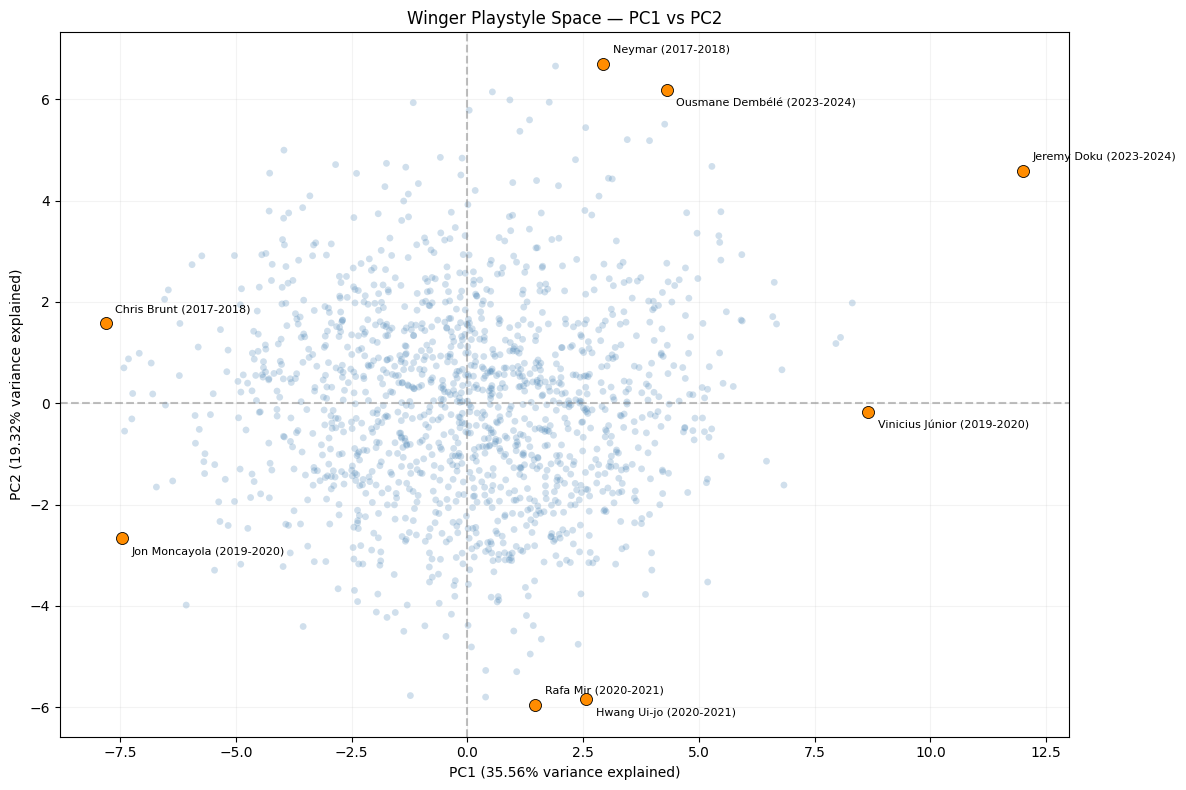

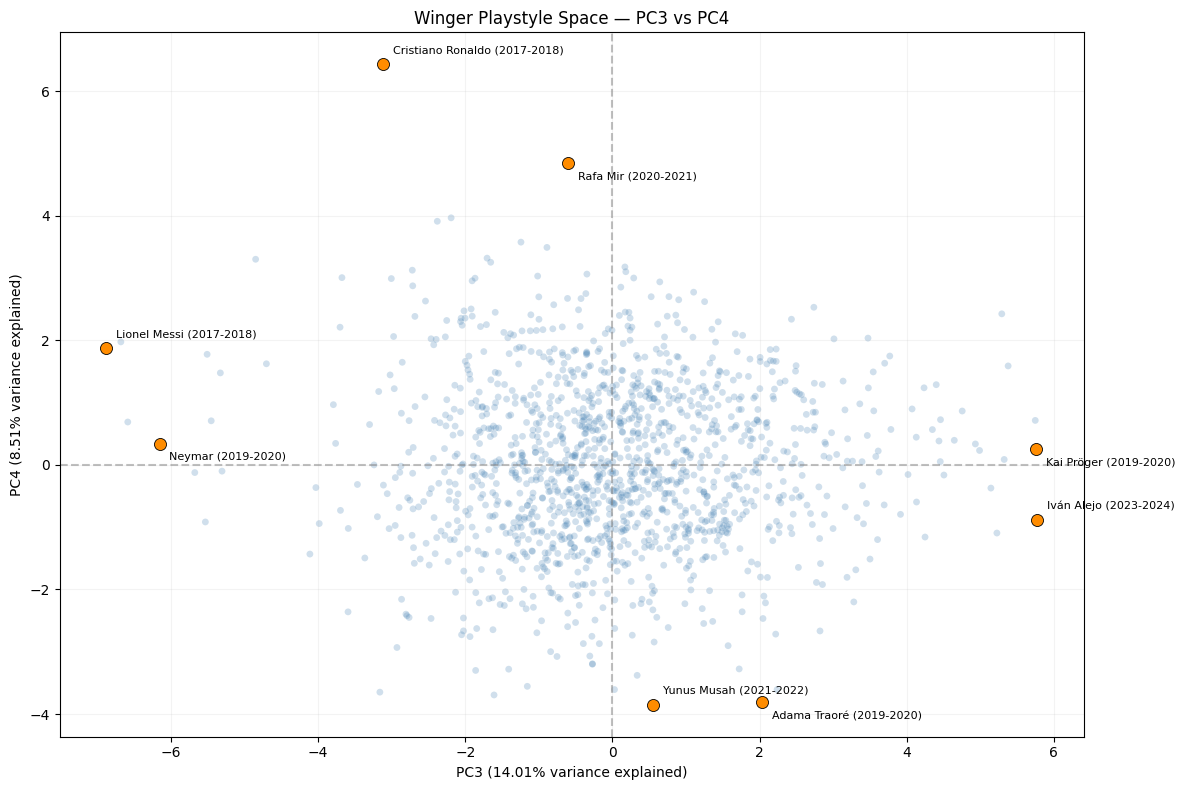

In [14]:
def plot_pca_projection(
    df,
    pc_x,
    pc_y,
    n_extremes=2
):

    fig, ax = plt.subplots(figsize=(12, 8))

    # Entire historical winger population
    ax.scatter(
        df[pc_x],
        df[pc_y],
        alpha=0.25,
        s=24,
        color="steelblue",
        edgecolors="none"
    )

    # Select a small number of distinct player spells
    # from each positive and negative extreme.
    selected_indices = []

    for pc in [pc_x, pc_y]:

        for ascending in [False, True]:

            subset = (
                df.sort_values(
                    pc,
                    ascending=ascending
                )
                .drop_duplicates("player_id")
                .head(n_extremes)
            )

            selected_indices.extend(subset.index.tolist())

    selected_indices = list(
        dict.fromkeys(selected_indices)
    )

    selected = df.loc[selected_indices]

    # Highlight illustrative observations
    ax.scatter(
        selected[pc_x],
        selected[pc_y],
        s=75,
        color="darkorange",
        edgecolor="black",
        linewidth=0.6,
        zorder=5
    )

    for i, (_, row) in enumerate(selected.iterrows()):

        offset = (7, 8) if i % 2 == 0 else (7, -12)

        ax.annotate(
            f"{row['player']} ({row['season']})",
            xy=(row[pc_x], row[pc_y]),
            xytext=offset,
            textcoords="offset points",
            fontsize=8
        )

    # Zero lines show mean component scores,
    # not group boundaries.
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.5)

    x_var = variance_df.loc[
        variance_df["component"] == pc_x,
        "explained_variance_pct"
    ].iloc[0]

    y_var = variance_df.loc[
        variance_df["component"] == pc_y,
        "explained_variance_pct"
    ].iloc[0]

    ax.set_xlabel(
        f"{pc_x} ({x_var:.2f}% variance explained)"
    )

    ax.set_ylabel(
        f"{pc_y} ({y_var:.2f}% variance explained)"
    )

    ax.set_title(
        f"Winger Playstyle Space — {pc_x} vs {pc_y}"
    )

    ax.grid(alpha=0.15)

    plt.tight_layout()
    plt.show()


plot_pca_projection(
    player_pca_df,
    "PC1",
    "PC2"
)

plot_pca_projection(
    player_pca_df,
    "PC3",
    "PC4"
)


## 3.2 Population Density Across PCA Dimensions

Scatterplots can make dense regions difficult to interpret because
many player observations overlap.

To better inspect population concentration, we construct
two-dimensional hexagonal density plots.

Each hexagon represents a region of PCA score space, with colour
indicating the number of player-spell observations within it.

These plots help distinguish:

- highly populated areas of the observed playstyle space;
- comparatively sparse regions;
- isolated player-spell observations.

Density concentrations are descriptive properties of the projected
data, not evidence that discrete player archetypes necessarily exist.

Because the analysis uses player × club × season observations,
footballers represented across multiple seasons contribute multiple
observations to these density distributions.

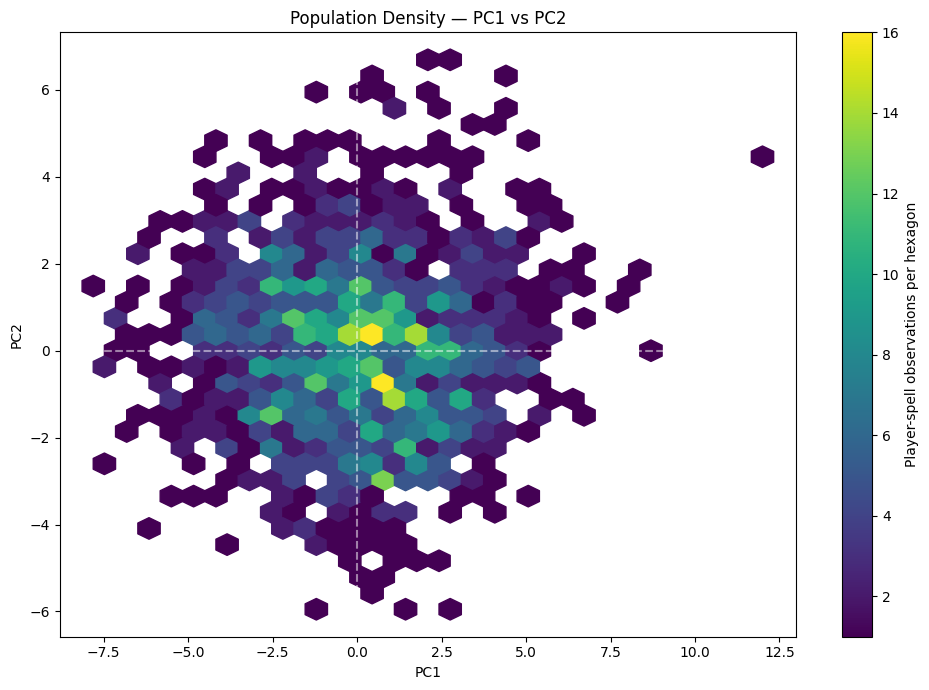

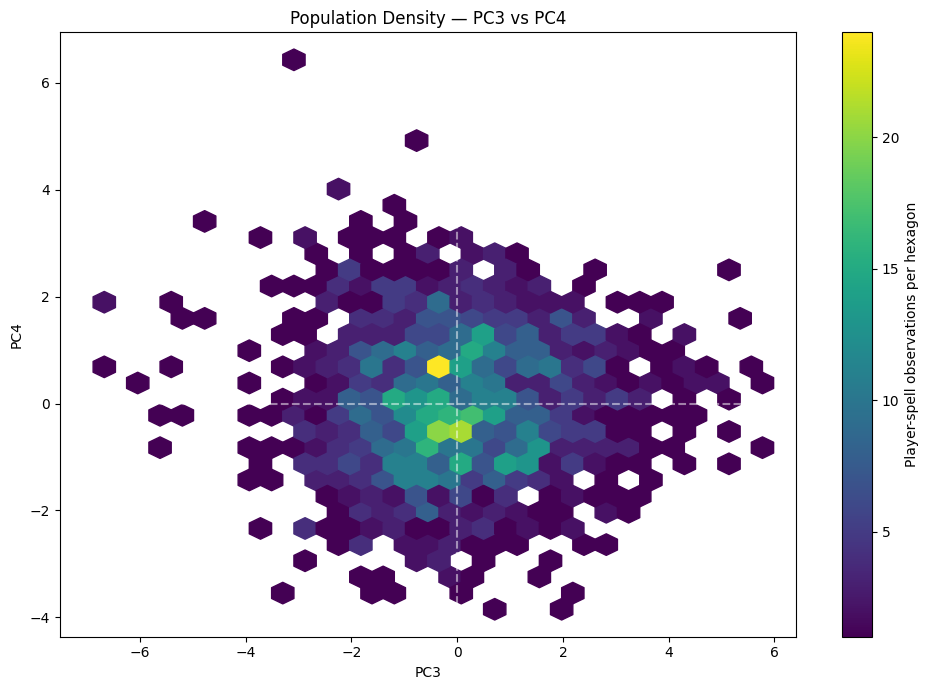

In [15]:
def plot_pca_density(df, pc_x, pc_y):

    fig, ax = plt.subplots(figsize=(10, 7))

    hb = ax.hexbin(
        df[pc_x],
        df[pc_y],
        gridsize=30,
        cmap="viridis",
        mincnt=1
    )

    cbar = fig.colorbar(hb, ax=ax)
    cbar.set_label(
        "Player-spell observations per hexagon"
    )

    ax.axhline(0, color="white", linestyle="--", alpha=0.5)
    ax.axvline(0, color="white", linestyle="--", alpha=0.5)

    ax.set_xlabel(pc_x)
    ax.set_ylabel(pc_y)

    ax.set_title(
        f"Population Density — {pc_x} vs {pc_y}"
    )

    plt.tight_layout()
    plt.show()


plot_pca_density(
    player_pca_df,
    "PC1",
    "PC2"
)

plot_pca_density(
    player_pca_df,
    "PC3",
    "PC4"
)


## 3.2 Findings — Geometry of the Winger Playstyle Space

The two-dimensional PCA projections reveal broadly continuous distributions, with concentrations of player-spell observations near the centre and relatively sparse extremes.

### PC1–PC2: Dominant Attacking Dimensions

The PC1–PC2 projection captures 54.88% of the total standardized feature variance.

Most observations occupy a connected, centrally concentrated region, with several extreme player spells extending away from the main distribution.

The positions of Jérémy Doku, Vinícius Júnior and Neymar illustrate how footballers with prominent attacking involvement can differ across the two leading dimensions.

In particular, high carry-led penetration does not necessarily imply equally high attacking-delivery activity.

### PC3–PC4: More Specific Behavioural Distinctions

The PC3–PC4 projection captures a further 22.52% of total variance.

The player extremes are consistent with the earlier component interpretations:

- PC3 distinguishes crossing-oriented distribution from progressive passing.
- PC4 distinguishes shooting frequency from take-on activity.

Players such as Cristiano Ronaldo, Lionel Messi, Adama Traoré and Iván Alejo illustrate different combinations of these behaviours.

### Population Density and Structural Interpretation

Both density plots show substantial central concentration, with observation counts generally declining toward the extremes.

Neither projection reveals clearly separated groups or obvious natural boundaries between player types.

Instead, the observed patterns suggest gradual variation across multiple attacking behaviours.

This supports treating winger playstyles as continuous, multidimensional profiles rather than assuming that every footballer belongs to a sharply defined archetype.

### Limitations

These findings describe two-dimensional projections, not the complete 20-dimensional feature space.

Separate groups could overlap in projection, while apparent visual separation does not necessarily imply meaningful clustering in higher dimensions.

Additionally, the observational unit is player × club × season. Players appearing in multiple seasons contribute multiple observations to the distributions.

### Conclusion

The PCA projections support the football interpretability of the leading components and reveal a broadly continuous distribution of attacking styles.

No clear evidence of discrete player groups emerges from these visualizations alone.

Before deciding whether dimensionality reduction or clustering is appropriate, we next investigate whether the observed component structure is robust to alternative feature-family weighting.



# 4. Family-Balanced PCA Sensitivity Analysis

## 4.1 Motivation and Methodology

The primary PCA assigns equal weight to each of the 20 standardized behavioural features.

However, these variables are distributed unequally across eight conceptual families:

- Territory
- Receiving
- Carrying
- Dribbling
- Passing
- Crossing
- Shooting
- Behavioural Choice

Families containing more features may exert greater aggregate influence on the geometry of the representation.

Additionally, correlated variables within a family may reinforce particular behavioural directions.

To investigate this, Notebook 04 constructed a family-balanced representation using:

$$
w_j = \frac{1}{\sqrt{n_f}}
$$

where \(n_f\) is the number of retained features in feature \(j\)'s behavioural family.

Each standardized feature was multiplied by its family weight.

This gives each family an equal sum of individual feature variances, although correlations mean that equal influence on individual principal components is not guaranteed.

### Objectives

We compare PCA fitted to the primary standardized matrix and the family-balanced matrix.

The comparison examines:

1. Whether explained variance remains similarly concentrated.
2. Whether the leading component score patterns remain aligned.
3. Whether the football interpretations of the leading dimensions remain consistent.

### Important methodological distinction

The family-balanced matrix is **not standardized again** before PCA, as doing so would undo the deliberate family weights.

The two PCA models are fitted independently.

Their component numbering and signs need not match, so direct PC1-to-PC1 comparisons alone are insufficient.

This sensitivity analysis tests whether the observed structure depends strongly on our feature-weighting choices.

It does not establish which weighting scheme is objectively correct.


In [16]:
# Retained features and their assigned families
family_info = feature_spec.set_index("feature").loc[features]

family_counts = (
    family_info["macro_family"].value_counts()
)

# Expected weights from Notebook 04
expected_weights = family_info["macro_family"].map(
    lambda family: 1 / np.sqrt(family_counts[family])
)

saved_weights = family_info["family_weight"]

np.testing.assert_allclose(
    saved_weights.to_numpy(dtype=float),
    expected_weights.to_numpy(dtype=float),
    rtol=1e-8
)

# Load the existing balanced matrix without refitting a scaler
X_balanced = balanced_df[features].copy()

expected_balanced = X.mul(
    saved_weights,
    axis=1
)

np.testing.assert_allclose(
    X_balanced.to_numpy(),
    expected_balanced.to_numpy(),
    rtol=1e-6,
    atol=1e-6
)

# Aggregate feature variance by family
family_variance = (
    X_balanced.var(ddof=0)
    .groupby(family_info["macro_family"])
    .sum()
)

family_audit = pd.DataFrame({
    "n_features": family_counts,
    "total_feature_variance": family_variance
})

print("Family-balanced representation verified.")

display(family_audit.round(4))

print(
    "\nTotal variance in balanced representation:",
    round(X_balanced.var(ddof=0).sum(), 4)
)

Family-balanced representation verified.


,n_features,total_feature_variance
macro_family,,
Behavioural Choice,2,1.0
Carrying,3,1.0
Crossing,2,1.0
Dribbling,2,1.0
Passing,4,1.0
Receiving,2,1.0
Shooting,3,1.0
Territory,2,1.0



Total variance in balanced representation: 8.0


Primary vs Family-Balanced PCA


,component,explained_variance_pct,cumulative_variance_pct,balanced_explained_pct,balanced_cumulative_pct
0,PC1,35.56,35.56,38.44,38.44
1,PC2,19.32,54.88,18.90,57.34
2,PC3,14.01,68.89,12.32,69.66
3,PC4,8.51,77.40,9.29,78.94
4,PC5,7.83,85.23,6.83,85.77
5,PC6,3.34,88.57,3.36,89.13
6,PC7,2.86,91.43,2.57,91.70
7,PC8,2.16,93.60,2.16,93.86
8,PC9,1.78,95.38,1.69,95.55
9,PC10,1.22,96.60,1.42,96.97


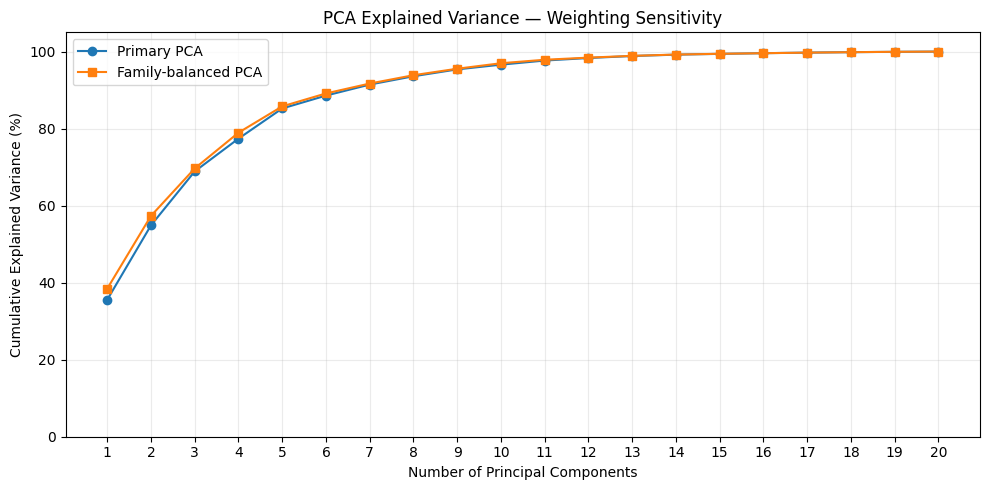

In [17]:
# PCA on the pre-weighted representation
pca_balanced = PCA()

balanced_pca_scores = pca_balanced.fit_transform(
    X_balanced
)

balanced_pc_names = [
    f"PC{i}"
    for i in range(1, pca_balanced.n_components_ + 1)
]

balanced_scores_df = pd.DataFrame(
    balanced_pca_scores,
    index=X_balanced.index,
    columns=balanced_pc_names
)

balanced_variance_df = pd.DataFrame({
    "component": balanced_pc_names,
    "balanced_explained_pct": (
        pca_balanced.explained_variance_ratio_ * 100
    )
})

balanced_variance_df["balanced_cumulative_pct"] = (
    balanced_variance_df["balanced_explained_pct"].cumsum()
)

# Comparison with primary PCA
variance_comparison = variance_df[
    [
        "component",
        "explained_variance_pct",
        "cumulative_variance_pct"
    ]
].merge(
    balanced_variance_df,
    on="component"
)

print("Primary vs Family-Balanced PCA")

display(
    variance_comparison.head(10).round(2)
)

# Compare cumulative variance curves
fig, ax = plt.subplots(figsize=(10, 5))

components = np.arange(1, 21)

ax.plot(
    components,
    variance_comparison["cumulative_variance_pct"],
    marker="o",
    label="Primary PCA"
)

ax.plot(
    components,
    variance_comparison["balanced_cumulative_pct"],
    marker="s",
    label="Family-balanced PCA"
)

ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance (%)")

ax.set_title(
    "PCA Explained Variance — Weighting Sensitivity"
)

ax.set_xticks(components)
ax.set_ylim(0, 105)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

Primary–Balanced PCA Score Correlations


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
PC1,0.999,-0.027,0.005,-0.004,-0.009,-0.030,0.008,0.000
PC2,0.023,0.923,0.374,-0.038,0.016,-0.024,0.053,0.007
PC3,0.015,0.377,-0.905,0.169,-0.020,-0.013,-0.080,-0.013
PC4,0.004,0.018,-0.145,-0.765,0.624,0.014,-0.044,-0.014
PC5,0.009,-0.026,0.086,0.614,0.778,-0.043,0.006,0.055


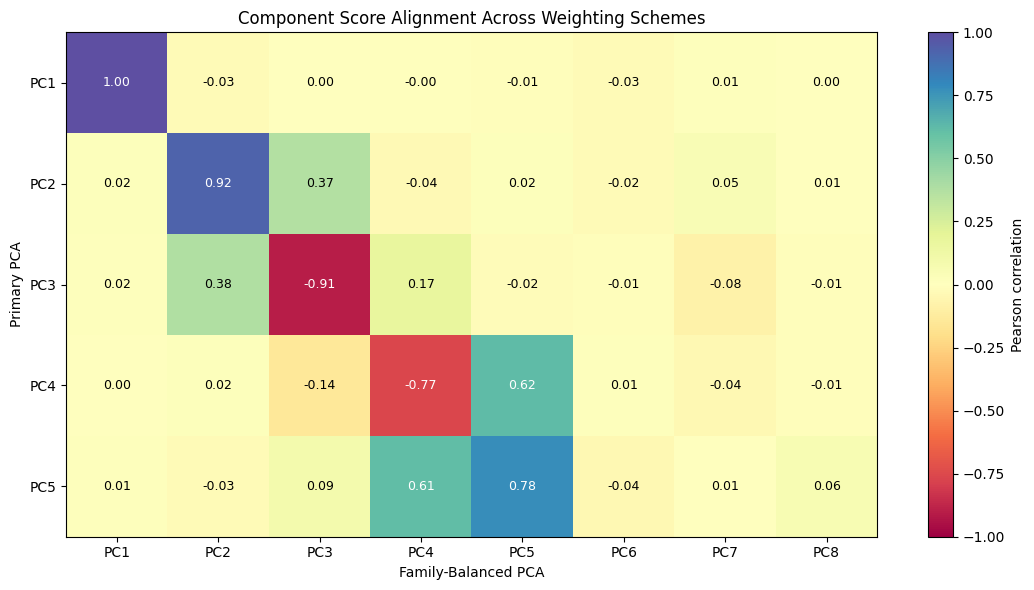

In [19]:
primary_pcs = focus_pcs

comparison_balanced_pcs = balanced_pc_names[:8]

score_alignment = pd.DataFrame(
    index=primary_pcs,
    columns=comparison_balanced_pcs,
    dtype=float
)

for primary_pc in primary_pcs:

    for balanced_pc in comparison_balanced_pcs:

        score_alignment.loc[
            primary_pc, balanced_pc
        ] = scores_df[primary_pc].corr(
            balanced_scores_df[balanced_pc]
        )

print("Primary–Balanced PCA Score Correlations")

display(score_alignment.round(3))


# Heatmap
fig, ax = plt.subplots(figsize=(11, 6))

im = ax.imshow(
    score_alignment.values,
    cmap="Spectral",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(comparison_balanced_pcs)),
    labels=comparison_balanced_pcs
)

ax.set_yticks(
    np.arange(len(primary_pcs)),
    labels=primary_pcs
)

ax.set_xlabel("Family-Balanced PCA")
ax.set_ylabel("Primary PCA")

ax.set_title(
    "Component Score Alignment Across Weighting Schemes"
)

for i in range(len(primary_pcs)):
    for j in range(len(comparison_balanced_pcs)):

        value = score_alignment.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(value) > 0.6 else "black"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Pearson correlation"
)

plt.tight_layout()
plt.show()


## 4.2 Initial Findings — Explained Variance and Component Alignment

The family-balanced PCA produces a variance distribution closely
resembling the primary PCA.

The first five components explain:

- Primary PCA: 85.23%
- Family-balanced PCA: 85.77%

The difference of 0.54 percentage points indicates that the
concentration of variance in the leading components is largely
preserved under alternative family weighting.

### Component Alignment

Comparing observation-level component scores reveals:

- **PC1:** Near-perfect alignment (+1.00), indicating a highly
  stable dominant behavioural direction.

- **PC2:** Strong alignment with balanced PC2 (+0.92), with
  some mixing involving balanced PC3 (+0.37).

- **PC3:** Strong alignment with balanced PC3 (-0.91), with
  additional mixing involving balanced PC2 (+0.38).

- **PC4 and PC5:** Substantial mixing between the fourth and
  fifth balanced components, suggesting rotation of these
  dimensions under alternative weighting.

Negative correlations do not imply disagreement by themselves,
because PCA component signs are arbitrary.

### Preliminary Interpretation

The leading PCA structure appears robust to family balancing,
particularly PC1–PC3.

However, the separate orientations of PC4 and PC5 are less stable
than their combined representation may be.

We therefore examine component subspace alignment before drawing
final conclusions about structural robustness.

In [20]:
from scipy.linalg import subspace_angles

def compare_subspaces(
    primary_scores,
    balanced_scores,
    primary_components,
    balanced_components
):

    A = primary_scores[
        primary_components
    ].to_numpy()

    B = balanced_scores[
        balanced_components
    ].to_numpy()

    angles = subspace_angles(A, B)
    angles_deg = np.degrees(angles)

    return {
        "primary_components": ", ".join(primary_components),
        "balanced_components": ", ".join(balanced_components),
        "max_angle_deg": angles_deg.max(),
        "mean_angle_deg": angles_deg.mean(),
        "min_angle_deg": angles_deg.min(),
        "mean_squared_cosine": np.mean(
            np.cos(angles) ** 2
        )
    }


subspace_results = []

# Leading component
subspace_results.append(
    compare_subspaces(
        scores_df,
        balanced_scores_df,
        ["PC1"],
        ["PC1"]
    )
)

# PC2-PC3 plane
subspace_results.append(
    compare_subspaces(
        scores_df,
        balanced_scores_df,
        ["PC2", "PC3"],
        ["PC2", "PC3"]
    )
)

# PC4-PC5 plane
subspace_results.append(
    compare_subspaces(
        scores_df,
        balanced_scores_df,
        ["PC4", "PC5"],
        ["PC4", "PC5"]
    )
)

# Complete leading five-dimensional subspace
subspace_results.append(
    compare_subspaces(
        scores_df,
        balanced_scores_df,
        ["PC1", "PC2", "PC3", "PC4", "PC5"],
        ["PC1", "PC2", "PC3", "PC4", "PC5"]
    )
)

subspace_audit = pd.DataFrame(subspace_results)

display(subspace_audit.round(4))

,primary_components,balanced_components,max_angle_deg,mean_angle_deg,min_angle_deg,mean_squared_cosine
0,PC1,PC1,2.9216,2.9216,2.9216,0.9974
1,"PC2, PC3","PC2, PC3",11.7193,7.8491,3.9788,0.9770
2,"PC4, PC5","PC4, PC5",11.2319,7.6432,4.0546,0.9785
3,"PC1, PC2, PC3, PC4, PC5","PC1, PC2, PC3, PC4, PC5",6.9891,3.9776,1.8141,0.9940


In [21]:
# Feature correlations with balanced component scores.
# Use original standardized X for comparable interpretation.

balanced_feature_corr = pd.DataFrame({
    pc: X.corrwith(balanced_scores_df[pc])
    for pc in focus_pcs
})

for pc in ["PC4", "PC5"]:

    print("\n" + "=" * 65)
    print(f"{pc} — PRIMARY PCA")
    print("=" * 65)

    primary_top = (
        feature_pc_corr[pc]
        .reindex(
            feature_pc_corr[pc]
            .abs()
            .sort_values(ascending=False)
            .index
        )
        .head(8)
    )

    display(primary_top.round(3).to_frame("correlation"))

    print(f"\n{pc} — FAMILY-BALANCED PCA")

    balanced_top = (
        balanced_feature_corr[pc]
        .reindex(
            balanced_feature_corr[pc]
            .abs()
            .sort_values(ascending=False)
            .index
        )
        .head(8)
    )

    display(balanced_top.round(3).to_frame("correlation"))


PC4 — PRIMARY PCA


,correlation
shots_p90,0.700
shots_per_100_att3rd_touches,0.624
take_ons_per_100_live_touches,-0.371
take_ons_p90,-0.369
attacking_third_touch_share,0.280
box_penetration_touch_share,0.266
progressive_reception_share,0.259
progressive_receptions_p90,0.238



PC4 — FAMILY-BALANCED PCA


,correlation
take_ons_per_100_live_touches,0.566
progressive_receptions_p90,-0.486
take_ons_p90,0.475
shots_p90,-0.390
attacking_third_touch_share,-0.356
passes_into_box_p90,-0.347
progressive_reception_share,-0.335
avg_shot_distance,0.288



PC5 — PRIMARY PCA


,correlation
shots_per_100_att3rd_touches,0.574
avg_shot_distance,0.507
take_ons_per_100_live_touches,0.441
progressive_receptions_p90,-0.427
take_ons_p90,0.355
shots_p90,0.325
progressive_reception_share,-0.290
long_pass_share,0.274



PC5 — FAMILY-BALANCED PCA


,correlation
shots_per_100_att3rd_touches,0.829
shots_p90,0.695
avg_shot_distance,0.393
long_pass_share,0.348
progressive_receptions_p90,-0.198
box_penetration_touch_share,0.150
progressive_pass_share,0.149
cross_pass_share,0.148



## 4.3 Final Findings — Family-Weighting Robustness

The family-balanced PCA sensitivity analysis indicates that the dominant
behavioural structure is highly consistent across the two weighting schemes.

### Explained Variance

The first five components explain:

- Primary PCA: 85.23%
- Family-balanced PCA: 85.77%

This similarity suggests that the concentration of variance in the leading
components is not strongly dependent on equal individual-feature weighting.

### Component Alignment

The dominant first component is exceptionally stable, with a score
correlation close to +1.00 and a principal angle of 2.92°.

PC2 and PC3 also remain strongly recognizable under family balancing,
although their directions exhibit modest mixing.

PC4 and PC5 demonstrate more substantial individual-axis rotation.

The family-balanced representation separates shooting and take-on
tendencies somewhat differently:

- Balanced PC4 emphasizes take-on activity against progressive receiving
  and shooting involvement.
- Balanced PC5 more clearly emphasizes shooting frequency and propensity.

This suggests that shooting, dribbling and receiving remain important
behavioural distinctions, but their allocation between individual
principal components depends partly on feature weighting.

### Subspace Stability

Comparing component subspaces confirms strong structural alignment:

| Subspace | Maximum Principal Angle | Mean Squared Cosine |
|---|---:|---:|
| PC1 | 2.92° | 0.9974 |
| PC2–PC3 | 11.72° | 0.9770 |
| PC4–PC5 | 11.23° | 0.9785 |
| PC1–PC5 | 6.99° | 0.9940 |

The complete five-dimensional subspace is highly aligned across
weighting schemes.

This indicates that family balancing largely preserves the dominant
patterns of variation among player-spell observations, even where
individual component axes rotate.

### Methodological Decision

The sensitivity results provide no compelling reason to replace the
primary standardized representation with the family-balanced version.

The primary PCA remains the reference for behavioural interpretation,
while the family-balanced representation remains an alternative
representation for robustness analysis.

However, stable component subspaces do not guarantee identical
player-to-player distances or nearest-neighbour rankings.

Neither weighting scheme has yet been established as superior for
player similarity or clustering.

The first five components are therefore retained as an interpretable
structural summary, not automatically adopted as the final modelling
representation.


# 5. Evaluating PCA for Downstream Player Similarity

## 5.1 Nearest-Neighbour Preservation

The first five principal components capture 85.23% of total
standardized feature variance.

However, explained variance is a global property of the dataset.
It does not directly measure the preservation of local player
relationships.

A dimensionality-reduced representation can preserve most
overall variance while changing which footballers appear
most stylistically similar.

To investigate this, we compare nearest-neighbour relationships
across three representations:

1. The full 20-feature standardized matrix.
2. The first five unwhitened PCA scores.
3. The full 20-feature family-balanced matrix.

Euclidean distance is used consistently for this diagnostic.

For each player spell, we identify its ten nearest neighbours and
measure how many are shared with the primary full-feature representation.

Other observations belonging to the same player_id are excluded
from neighbour selection to avoid repeated seasons of the same
footballer inflating apparent cross-player agreement.

This exclusion affects only the diagnostic, not the underlying
observational grain or PCA fit.

The comparison evaluates representation sensitivity rather than
establishing which neighbour rankings are objectively correct.

No final similarity metric or representation is selected in advance.

In [22]:
from sklearn.metrics import pairwise_distances

def get_neighbours(matrix, player_ids, k=10):

    distances = pairwise_distances(
        matrix,
        metric="euclidean"
    )

    # Exclude all observations belonging to the same footballer
    same_player = (
        player_ids[:, None] == player_ids[None, :]
    )

    distances[same_player] = np.inf

    assert (np.isfinite(distances).sum(axis=1) >= k).all()

    return np.argpartition(
        distances,
        kth=k - 1,
        axis=1
    )[:, :k]


player_ids = scaled_df["player_id"].to_numpy()

k = 10

# Full standardized feature representation
neighbours_full = get_neighbours(
    X.to_numpy(),
    player_ids,
    k
)

# PCA-reduced representation (no whitening)
neighbours_pca5 = get_neighbours(
    scores_df[focus_pcs].to_numpy(),
    player_ids,
    k
)

# Full family-balanced representation
neighbours_balanced = get_neighbours(
    X_balanced.to_numpy(),
    player_ids,
    k
)


def neighbour_overlap(reference, alternative, k=10):

    return np.array([
        len(set(a) & set(b)) / k
        for a, b in zip(reference, alternative)
    ])


overlap_pca5 = neighbour_overlap(
    neighbours_full,
    neighbours_pca5,
    k
)

overlap_balanced = neighbour_overlap(
    neighbours_full,
    neighbours_balanced,
    k
)


comparison = pd.DataFrame({
    "representation": [
        "PCA — 5 components",
        "Family-balanced — 20 features"
    ],
    "mean_overlap": [
        overlap_pca5.mean(),
        overlap_balanced.mean()
    ],
    "median_overlap": [
        np.median(overlap_pca5),
        np.median(overlap_balanced)
    ],
    "10th_percentile_overlap": [
        np.percentile(overlap_pca5, 10),
        np.percentile(overlap_balanced, 10)
    ],
    "pct_spells_3plus_changed": [
        (overlap_pca5 <= 0.7).mean() * 100,
        (overlap_balanced <= 0.7).mean() * 100
    ]
})

display(comparison.round(3))

,representation,mean_overlap,median_overlap,10th_percentile_overlap,pct_spells_3plus_changed
0,PCA — 5 components,0.542,0.5,0.3,87.679
1,Family-balanced — 20 features,0.853,0.9,0.7,11.748



## 5.2 Findings — PCA and Local Similarity Preservation

The first five principal components explain 85.23% of total
standardized feature variance.

However, retaining this proportion of variance does not guarantee
preservation of local player-to-player relationships.

### Five-Component PCA

Compared with the complete 20-feature standardized representation:

- Mean top-10 neighbour overlap: 54.2%
- Median overlap: 50%
- 10th-percentile overlap: 30%
- Player spells losing at least three neighbours: 87.68%

The reduced PCA representation therefore changes local player
neighbourhoods substantially.

Although five components summarize the dominant directions of
variation, the discarded dimensions remain relevant to
distinguishing some otherwise similar player profiles.

### Family-Balanced Representation

The family-balanced 20-feature representation produces:

- Mean top-10 neighbour overlap: 85.3%
- Median overlap: 90%
- 10th-percentile overlap: 70%
- Player spells losing at least three neighbours: 11.75%

Most local relationships are preserved under family balancing,
although some changes remain.

This suggests that the observed similarity structure is
reasonably robust to alternative family weighting.

However, neighbour overlap measures agreement with the primary
representation, not agreement with independent football evidence.

### Representation Decision

**Primary baseline:** All 20 globally standardized behavioural
features.

**Sensitivity representation:** All 20 family-balanced behavioural
features.

**PCA:** Retained for dimensional interpretation, visualization,
and structural investigation.

Five-component PCA will not be adopted as the default player
similarity representation because it substantially changes the
nearest-neighbour relationships.

### Remaining Limitation

The choice of Euclidean distance is not yet final.

Future similarity analysis must examine whether the resulting
player comparisons are consistent with football interpretation,
and whether important relationships remain stable under alternative
weighting and reasonable methodological choices.

Quality and output statistics remain outside the style-distance
calculation.


# 6. Conclusions and Downstream Implications

## 6.1 Summary of Findings

This notebook investigated the dimensional structure of attacking
behaviour among 1,396 historical winger player-club-season spells.

The analysis produced five principal findings.

### 1. Winger Playstyle Variation Has a Strong Low-Dimensional Structure

The first five principal components explain 85.23% of total
standardized feature variance.

The leading dimensions capture substantial shared variation
among the 20 engineered attacking behaviours.

### 2. The Leading Components Are Football-Interpretable

Feature correlations and player-level examples suggest:

- PC1: Carry-led advanced attacking penetration versus a more
  passing-oriented role.
- PC2: Attacking delivery versus direct penalty-area involvement.
- PC3: Crossing orientation versus progressive passing.
- PC4: Shooting tendency versus take-on activity.
- PC5: Take-on intensity and longer-range shooting versus
  progressive receiving.

These are provisional interpretations of continuous statistical
dimensions, not discrete tactical archetypes.

### 3. Playstyle Distributions Appear Broadly Continuous

The examined two-dimensional PCA projections show central
concentrations and relatively sparse extremes.

No clearly separated groups are visually apparent.

This does not rule out meaningful higher-dimensional structure,
but cautions against assuming that player archetypes must exist
as sharply separated categories.

### 4. Dominant Structure Is Robust to Family Balancing

The primary and family-balanced PCA representations show highly
similar explained-variance distributions.

Their leading five-dimensional score subspaces are strongly
aligned, with a maximum principal angle of 6.99° and a mean
squared cosine of 0.9940.

Individual PC4 and PC5 axes rotate under family weighting,
although their combined subspace remains stable.

### 5. PCA Reduction Changes Local Player Similarity

Despite explaining 85.23% of variance, five-component PCA
preserves only 54.2% of the primary representation's top-ten
neighbours on average.

The complete family-balanced representation preserves 85.3%.

This demonstrates that preserving global variance does not
necessarily preserve local stylistic relationships.

## 6.2 Final Methodological Decisions

The project will retain all 20 standardized behavioural features
as the primary baseline for player-style similarity analysis.

The 20-feature family-balanced representation will be retained
for sensitivity analysis.

PCA will be used primarily to interpret and visualize the
underlying structure of attacking behaviour.

No discrete player archetypes have been established at this stage.

## 6.3 Next Research Stage

The next stage will examine player-to-player stylistic similarity.

Its central questions are:

1. Which players exhibit the most similar attacking behaviours?
2. Do these comparisons make sense when their actual feature
   profiles are inspected?
3. Which individual behaviours explain similarity and difference?
4. How sensitive are the comparisons to representation and
   distance choices?

Only after establishing credible player comparisons will the
project consider whether clustering adds meaningful football
information beyond continuous similarity profiles.

In [23]:
from pathlib import Path
import joblib

OUTPUT_05 = OUTPUT_DIR / "notebook_05_outputs"
OUTPUT_05.mkdir(parents=True, exist_ok=True)

# Validate consistency before exporting
assert scores_df.shape == (len(scaled_df), 20)
assert balanced_scores_df.shape == (len(scaled_df), 20)

np.testing.assert_allclose(
    pca.transform(X),
    scores_df.to_numpy(),
    atol=1e-8
)

np.testing.assert_allclose(
    pca_balanced.transform(X_balanced),
    balanced_scores_df.to_numpy(),
    atol=1e-8
)

# Preserve canonical identity alongside all PCA scores
primary_scores_export = pd.concat(
    [
        scaled_df[identity_cols].reset_index(drop=True),
        scores_df.reset_index(drop=True)
    ],
    axis=1
)

balanced_scores_export = pd.concat(
    [
        scaled_df[identity_cols].reset_index(drop=True),
        balanced_scores_df.reset_index(drop=True)
    ],
    axis=1
)

# PCA score outputs
primary_scores_export.to_parquet(
    OUTPUT_05 / "pca_primary_scores.parquet",
    index=False
)

balanced_scores_export.to_parquet(
    OUTPUT_05 / "pca_balanced_scores.parquet",
    index=False
)

# Feature coefficients and correlations
pca_coefficients.rename_axis("feature").to_csv(
    OUTPUT_05 / "pca_primary_coefficients.csv"
)

feature_pc_corr.rename_axis("feature").to_csv(
    OUTPUT_05 / "pca_primary_feature_correlations.csv"
)

balanced_feature_corr.rename_axis("feature").to_csv(
    OUTPUT_05 / "pca_balanced_feature_correlations.csv"
)

# Explained variance
variance_df.to_csv(
    OUTPUT_05 / "pca_primary_variance.csv",
    index=False
)

balanced_variance_df.to_csv(
    OUTPUT_05 / "pca_balanced_variance.csv",
    index=False
)

# Sensitivity diagnostics
subspace_audit.to_csv(
    OUTPUT_05 / "pca_subspace_alignment.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_05 / "pca_neighbour_preservation.csv",
    index=False
)

# Save fitted PCA objects
joblib.dump(
    pca,
    OUTPUT_05 / "pca_primary.joblib"
)

joblib.dump(
    pca_balanced,
    OUTPUT_05 / "pca_balanced.joblib"
)

print("Notebook 05 exports completed.")

for path in sorted(OUTPUT_05.iterdir()):
    print(path.name)

Notebook 05 exports completed.
pca_balanced.joblib
pca_balanced_feature_correlations.csv
pca_balanced_scores.parquet
pca_balanced_variance.csv
pca_neighbour_preservation.csv
pca_primary.joblib
pca_primary_coefficients.csv
pca_primary_feature_correlations.csv
pca_primary_scores.parquet
pca_primary_variance.csv
pca_subspace_alignment.csv


In [24]:
import shutil
from google.colab import files

shutil.make_archive('notebook_05_outputs', 'zip', OUTPUT_DIR/'notebook_05_outputs')

files.download('notebook_05_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>